In [110]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from sklearn.model_selection import (
    train_test_split,
    cross_validate
)
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    root_mean_squared_error
)
os.makedirs("plots", exist_ok=True)

In [111]:
SEED = 42

FEATURE_COLS = [
    "Age", "Weight_kg", "Height_m",
    "Max_BPM", "Avg_BPM", "Resting_BPM",
    "Session_Duration_min", "Fat_Percentage",
    "Water_Intake_liters", "BMI"
]

df = pd.read_csv(
    "../backend/data/gym_members_clean.csv"
)

X = df[FEATURE_COLS]
y = df["Calories_Burned"]

print(df.shape)
print(X.shape)
print(y.shape)

(973, 14)
(973, 10)
(973,)


In [112]:
Xtr, Xte, ytr, yte = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=SEED,
    stratify=df["Overtraining_Risk_Label"]
)

print("training set:" , Xtr.shape)
print("testing set:", Xte.shape)

training set: (778, 10)
testing set: (195, 10)


In [113]:
baseline = DummyRegressor(
    strategy="mean"
)

baseline.fit(Xtr, ytr)

baseline_pred = baseline.predict(Xte)

In [114]:
linear_model = LinearRegression()

linear_model.fit(Xtr, ytr)

linear_pred = linear_model.predict(Xte)

In [115]:
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    random_state=SEED
)

rf_model.fit(Xtr, ytr)

rf_pred = rf_model.predict(Xte)

In [116]:
def evaluate_model(model, X_test, y_test):
    predictions = model.predict(X_test)

    return {
        "R2": r2_score(y_test, predictions),

        "MAE": mean_absolute_error(
            y_test, predictions
        ),
        "RMSE": root_mean_squared_error(
            y_test, predictions
        )
    }    

In [117]:
models = {
    "Mean Baseline": baseline,
    "Linear Regression": linear_model,
    "Random Forest": rf_model
}

results = {}

for name, model in models.items():
    results[name] = evaluate_model(
        model, Xte, yte
    )

results_df = pd.DataFrame(results).T

print("\nTest Set Results:")

display(results_df.round(4))


Test Set Results:


,R2,MAE,RMSE
Mean Baseline,-0.0048,210.6926,264.5224
Linear Regression,0.9643,37.5623,49.8414
Random Forest,0.9652,38.1170,49.2088


In [118]:
cv_results = {}

for name, model in models.items():

    scores = cross_validate(
        model,
        Xtr,
        ytr,
        cv=5,
        scoring="r2"
    )

    cv_results[name] = scores["test_score"].mean()


cv_df = pd.DataFrame.from_dict(
    cv_results,
    orient="index",
    columns=["Mean CV R2"]
)

print("\nCross-Validation Results:")

display(cv_df.round(4))


Cross-Validation Results:


,Mean CV R2
Mean Baseline,-0.0061
Linear Regression,0.9725
Random Forest,0.9652


In [119]:

lr_name = next(
    name for name in models
    if "linear" in name.lower()
)

rf_name = next(
    name for name in models
    if "random forest" in name.lower()
)

lr_new_cv = cross_validate(
    models[lr_name],
    Xtr_new,
    ytr,
    cv=5,
    scoring="r2"
)

rf_new_cv = cross_validate(
    rf_new,
    Xtr_new,
    ytr,
    cv=5,
    scoring="r2"
)

cv_comparison = pd.DataFrame({
    "Original Mean CV R2": [
        cv_df.loc[lr_name, "Mean CV R2"],
        cv_df.loc[rf_name, "Mean CV R2"]
    ],
    "New Mean CV R2": [
        lr_new_cv["test_score"].mean(),
        rf_new_cv["test_score"].mean()
    ]
}, index=[lr_name, rf_name])

cv_comparison["Improvement"] = (
    cv_comparison["New Mean CV R2"]
    - cv_comparison["Original Mean CV R2"]
)

display(cv_comparison.round(4))

,Original Mean CV R2,New Mean CV R2,Improvement
Linear Regression,0.9725,0.9803,0.0078
Random Forest,0.9652,0.9838,0.0186


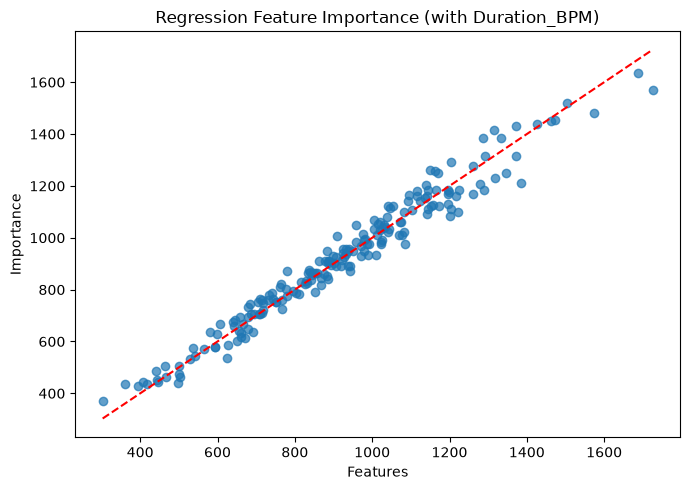

In [120]:

plt.figure(figsize=(7, 5))

plt.scatter(yte, rf_pred, alpha=0.7)

plt.plot(
    [yte.min(), yte.max()],
    [yte.min(), yte.max()],
    "r--"
)

plt.title("Regression Feature Importance (with Duration_BPM)")
plt.ylabel("Importance")
plt.xlabel("Features")

plt.tight_layout()

plt.savefig(
    "plots/regression_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

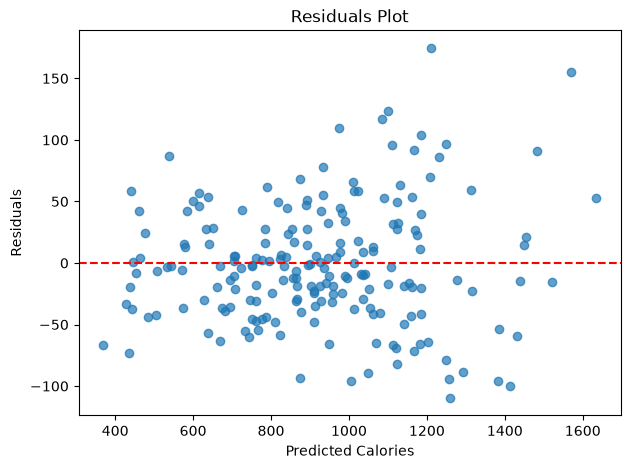

In [121]:
residuals = yte - rf_pred

plt.figure(figsize=(7, 5))

plt.scatter(rf_pred, residuals, alpha=0.7)

plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Calories")
plt.ylabel("Residuals")
plt.title("Residuals Plot")

plt.savefig(
    "plots/residuals.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [122]:
Xtr_new = Xtr.copy()
Xte_new = Xte.copy()

Xtr_new["Duration_BPM"] = (
    Xtr_new["Session_Duration_min"]
    * Xtr_new["Avg_BPM"]
)

Xte_new["Duration_BPM"] = (
    Xte_new["Session_Duration_min"]
    * Xte_new["Avg_BPM"]
)
print( "\nOriginal number of features:", Xtr.shape[1])

print( "New number of features:",  Xtr_new.shape[1])


Original number of features: 10
New number of features: 11


In [123]:
rf_new = RandomForestRegressor(
    n_estimators=200,
    max_depth=12,
    random_state=SEED
)

rf_new.fit(Xtr_new, ytr)
rf_new_results = evaluate_model(rf_new,Xte_new,yte)
print(rf_new_results["R2"])


0.9833950190556272


In [124]:
importance = pd.Series(
    rf_model.feature_importances_,
    index=FEATURE_COLS
)

importance = importance.sort_values(
    ascending=False
)

importance

Session_Duration_min    0.837545
Avg_BPM                 0.099484
Age                     0.021431
Fat_Percentage          0.014497
Weight_kg               0.007797
Water_Intake_liters     0.005545
Height_m                0.004802
BMI                     0.003745
Max_BPM                 0.002658
Resting_BPM             0.002496
dtype: float64

In [125]:
comparison_df = pd.DataFrame(
    {
        "Original RF": results_df.loc[
            "Random Forest"
        ],

        "RF with New Feature": rf_new_results
    }
).T

print("\nFeature Engineering Comparison:")

display(comparison_df.round(4))



Feature Engineering Comparison:


,R2,MAE,RMSE
Original RF,0.9652,38.1170,49.2088
RF with New Feature,0.9834,25.2621,34.0056


In [126]:
original_cv_r2 = cv_results["Random Forest"]

rf_new_cv = cross_validate(
    rf_new,
    Xtr_new,
    ytr,
    cv=5,
    scoring="r2"
)

new_cv_scores = rf_new_cv["test_score"]
new_cv_r2 = new_cv_scores.mean()
new_cv_std = new_cv_scores.std()

print("Original Random Forest CV R2:", round(float(original_cv_r2), 4))
print("New Random Forest CV R2 Mean:", round(float(new_cv_r2), 4))
print("New Random Forest CV R2 Std:", round(float(new_cv_std), 4))

if new_cv_r2 > original_cv_r2:
    print("The new feature improved the average CV R2.")
elif new_cv_r2 < original_cv_r2:
    print("The new feature reduced the average CV R2.")
else:
    print("The new feature did not change the average CV R2.")

Original Random Forest CV R2: 0.9652
New Random Forest CV R2 Mean: 0.9838
New Random Forest CV R2 Std: 0.0025
The new feature improved the average CV R2.


In [127]:
importance = pd.Series(
    rf_new.feature_importances_,
    index=Xtr_new.columns
)

importance = importance.sort_values(
    ascending=False
)

print("\nFeature Importance:")

display(importance)


Feature Importance:


Duration_BPM            0.949679
Age                     0.024390
Weight_kg               0.007854
Water_Intake_liters     0.006154
Fat_Percentage          0.004089
Height_m                0.003029
BMI                     0.001207
Avg_BPM                 0.001114
Max_BPM                 0.000876
Session_Duration_min    0.000848
Resting_BPM             0.000761
dtype: float64

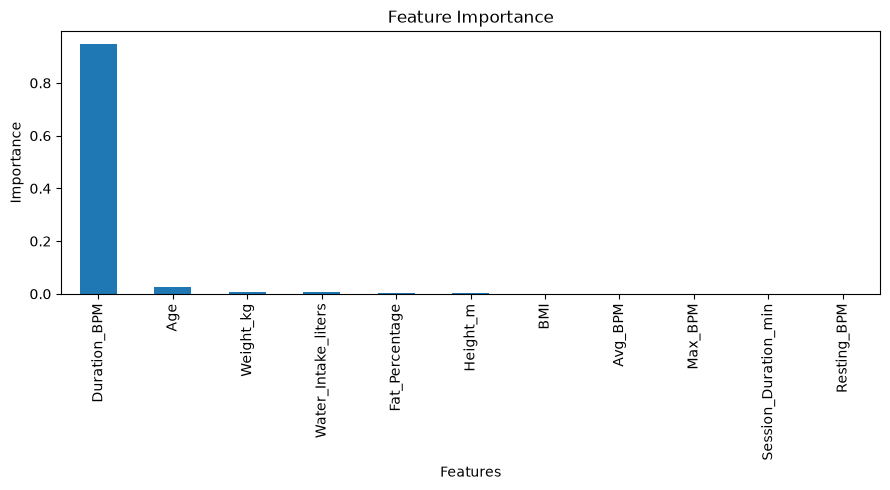

In [128]:
importance.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Feature Importance")

plt.ylabel("Importance")
plt.xlabel("Features")

plt.tight_layout()

plt.savefig(
    "plots/feature_importance.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

,Task,Model,Primary Metric,Secondary Metric
0,Classification (Member 3),Dummy (Majority),F1 = 0.7888,AUC = 0.5000
1,Classification (Member 3),Decision Tree (d=3),F1 = 0.9127,AUC = 0.9310
2,Classification (Member 3),Random Forest (10 feat),F1 = 0.9440,AUC = 0.9773
3,Classification (Member 3),Random Forest (13 feat),F1 = 0.9398,AUC = 0.9772
4,Regression (Member 4),Mean Baseline,R2 = -0.0048,RMSE = 264.52
5,Regression (Member 4),Linear Regression,R2 = 0.9643,RMSE = 49.84
6,Regression (Member 4),Random Forest (10 feat),R2 = 0.9652,RMSE = 49.21
7,Regression (Member 4),RF + Duration_BPM (11),R2 = 0.9834,RMSE = 34.01


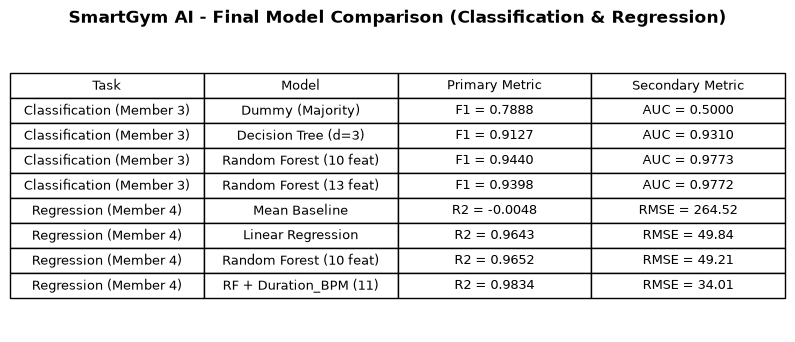

In [129]:
final_summary = pd.DataFrame([
    {
        "Task": "Classification (Member 3)",
        "Model": "Dummy (Majority)",
        "Primary Metric": "F1 = 0.7888",
        "Secondary Metric": "AUC = 0.5000"
    },
    {
        "Task": "Classification (Member 3)",
        "Model": "Decision Tree (d=3)",
        "Primary Metric": "F1 = 0.9127",
        "Secondary Metric": "AUC = 0.9310"
    },
    {
        "Task": "Classification (Member 3)",
        "Model": "Random Forest (10 feat)",
        "Primary Metric": "F1 = 0.9440",
        "Secondary Metric": "AUC = 0.9773"
    },
    {
        "Task": "Classification (Member 3)",
        "Model": "Random Forest (13 feat)",
        "Primary Metric": "F1 = 0.9398",
        "Secondary Metric": "AUC = 0.9772"
    },
    {
        "Task": "Regression (Member 4)",
        "Model": "Mean Baseline",
        "Primary Metric": f"R2 = {results_df.loc['Mean Baseline', 'R2']:.4f}",
        "Secondary Metric": f"RMSE = {results_df.loc['Mean Baseline', 'RMSE']:.2f}"
    },
    {
        "Task": "Regression (Member 4)",
        "Model": "Linear Regression",
        "Primary Metric": f"R2 = {results_df.loc['Linear Regression', 'R2']:.4f}",
        "Secondary Metric": f"RMSE = {results_df.loc['Linear Regression', 'RMSE']:.2f}"
    },
    {
        "Task": "Regression (Member 4)",
        "Model": "Random Forest (10 feat)",
        "Primary Metric": f"R2 = {results_df.loc['Random Forest', 'R2']:.4f}",
        "Secondary Metric": f"RMSE = {results_df.loc['Random Forest', 'RMSE']:.2f}"
    },
    {
        "Task": "Regression (Member 4)",
        "Model": "RF + Duration_BPM (11)",
        "Primary Metric": f"R2 = {rf_new_results['R2']:.4f}",
        "Secondary Metric": f"RMSE = {rf_new_results['RMSE']:.2f}"
    }
])

display(final_summary)

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.axis("off")

tbl = ax.table(
    cellText=final_summary.values,
    colLabels=final_summary.columns,
    loc="center",
    cellLoc="center"
)

tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
tbl.scale(1.0, 1.5)

plt.title(
    "SmartGym AI - Final Model Comparison (Classification & Regression)",
    pad=12,
    fontweight="bold"
)

plt.savefig(
    "plots/final_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Results Summary:

1. The Mean Baseline achieved R² = -0.0048 (RMSE = 264.52 kcal), proving that predicting the average is ineffective.

2. Linear Regression reached R² = 0.9643 (MAE = 37.56, RMSE = 49.84) on the shared test set, very close to Random Forest (R² = 0.9652, RMSE = 49.21).

3. This close performance happens because Calories_Burned scales almost linearly with Session_Duration_min and Avg_BPM (together >93% of RF importance).

4. Adding the interaction feature Duration_BPM = Session_Duration_min * Avg_BPM boosted Random Forest test R² to 0.9834 and improved 5-fold CV R² from 0.9652 to 0.9838, supporting the importance of the interaction between workout duration and average heart rate in predicting calorie burn.

5. Combined with Member 3's classification benchmarks (RF F1 = 0.9440 on 10 features, 0.9398 on 13 features), all models are summarized in final_model_comparison.png for the presentation.